# Retinal Blood Vessel Segmentation on DRIVE
**Frequency domain enhancement with a Gaussian band-pass filter**

**CLAHE** (an adaptive form of histogram equalization) and **removing small specks**
after thresholding.

Run the cells from top to bottom. All figures are also saved into a `figures/` folder
so you can put them straight onto your slides.

## 0. Get the DRIVE dataset

In [ ]:
!git clone -q --depth 1 --filter=blob:none --sparse https://github.com/sraashis/deepdyn.git
!cd deepdyn && git sparse-checkout set data/DRIVE

remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 5 (delta 0), reused 2 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (5/5), 65.49 KiB | 1.11 MiB/s, done.
remote: Enumerating objects: 121, done.
remote: Counting objects: 100% (121/121), done.
remote: Compressing objects: 100% (121/121), done.
remote: Total 121 (delta 0), reused 121 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (121/121), 28.19 MiB | 20.19 MiB/s, done.
Updating files: 100% (121/121), done.


## 1. Settings and imports

In [ ]:
import glob, os, re
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from skimage import exposure
from sklearn.metrics import roc_curve, roc_auc_score

DATA_DIR = "deepdyn/data/DRIVE"   # folder that contains the DRIVE images (searched recursively)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

EQUALIZATION = "clahe"    # "clahe" = adaptive histogram equalization, "global" = plain version, "none"
THRESHOLD_RULE = "dice"   # "dice" = threshold with the best overlap, "roc" = closest point to (0,1) like Yue (2023)
REMOVE_SPECKS = True      # delete tiny isolated blobs after thresholding
MIN_SPECK_SIZE = 30       # blobs smaller than this many pixels are removed

plt.rcParams["figure.dpi"] = 110


def show_row(images, titles, filename=None, cmap="gray", size=3.2):
    """Show several images side by side and optionally save the figure."""
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size * 1.1))
    for ax, im, t in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(im, cmap=cmap)
        ax.set_title(t, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    if filename:
        plt.savefig(os.path.join(FIG_DIR, filename), bbox_inches="tight", dpi=200)
    plt.show()

## 2. Load the dataset
DRIVE has 40 images. Each one comes with:
- the colour retina photo,
- a **manual vessel map** drawn by an expert (the "ground truth"),
- a **FOV mask**: the round area of the retina. We only measure pixels inside it.

The filter has two settings (D_low, D_high) and we need one
threshold T. These 3 numbers are chosen on the **tuning set** (images 21–40). The final
result is then measured once on the **evaluation set** (images 1–20). Choosing settings
on the same images we are measuring on would make the results look better than they really are.

Tuning set:     [21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]
Evaluation set: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Image size: (584, 565, 3). Vessel pixels inside the FOV: 13.1%


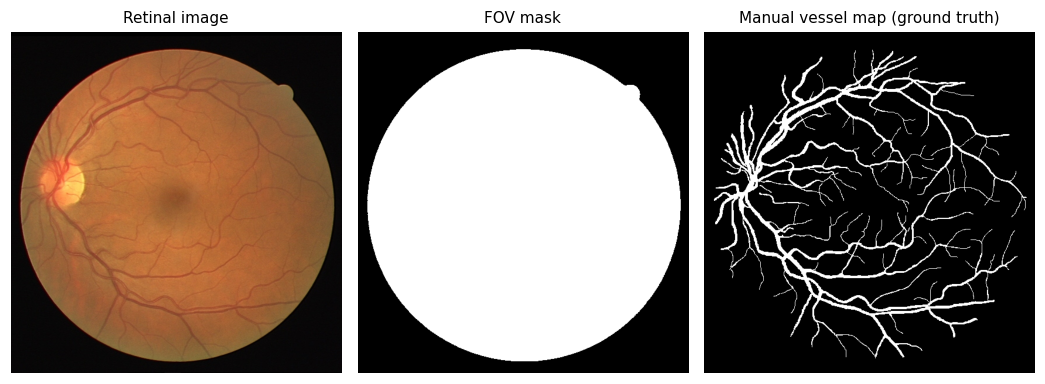

In [ ]:
def find_drive_cases(root):
    """Find every DRIVE case under `root`, whatever the folder layout is."""
    cases = {}
    for f in glob.glob(os.path.join(root, "**", "*"), recursive=True):
        name = os.path.basename(f).lower()
        m = re.match(r"(\d+)_", name)
        if not m or os.path.isdir(f):
            continue
        case = cases.setdefault(int(m.group(1)), {})
        if "manual1" in name:
            case["truth"] = f
        elif "manual2" in name:
            case["observer2"] = f
        elif "mask" in name:
            case["fov"] = f
        elif name.endswith((".tif", ".tiff")):
            case["image"] = f
    return cases


def load_case(case):
    rgb = np.array(Image.open(case["image"]).convert("RGB"))
    fov = np.array(Image.open(case["fov"]).convert("L")) > 128
    truth = np.array(Image.open(case["truth"]).convert("L")) > 128
    obs2 = None
    if "observer2" in case:
        obs2 = np.array(Image.open(case["observer2"]).convert("L")) > 128
    return dict(rgb=rgb, fov=fov, truth=truth, obs2=obs2)


cases = find_drive_cases(DATA_DIR)
labelled = sorted(k for k, c in cases.items() if {"image", "fov", "truth"} <= c.keys())
assert labelled, f"No DRIVE images found in '{DATA_DIR}'. Check DATA_DIR."

test_ids = [k for k in labelled if k <= 20]
tune_ids = [k for k in labelled if k >= 21]
if not test_ids:

    # split the 20 training images in half instead.
    tune_ids, test_ids = tune_ids[:10], tune_ids[10:]

data = {k: load_case(cases[k]) for k in tune_ids + test_ids}
print(f"Tuning set:     {tune_ids}")
print(f"Evaluation set: {test_ids}")

example_id = test_ids[0]
ex = data[example_id]
vessel_share = ex["truth"][ex["fov"]].mean()
print(f"Image size: {ex['rgb'].shape}. Vessel pixels inside the FOV: {vessel_share:.1%}")

show_row([ex["rgb"], ex["fov"], ex["truth"]],
         ["Retinal image", "FOV mask", "Manual vessel map (ground truth)"],
         "fig1_dataset.png")

## 3. Preprocessing
1. **Green channel** : blood absorbs green light, so vessels have the
   best contrast in this channel.
2. **Image negative** : `s = (L-1) - r`. Vessels change from dark to bright.
3. **CLAHE** (Contrast Limited Adaptive Histogram Equalization), an upgrade of the
   histogram equalization:
   - the image is split into small tiles (8×8 grid) and **each tile is equalized on its
     own**, so dark and bright parts of the retina both get good contrast;
   - each tile's histogram is **clipped** (`clip_limit = 0.01`) before equalizing, so
     noise is not boosted too much;
   - neighbouring tiles are blended smoothly, so no tile borders are visible.

   Plain (global) histogram equalization boosts the noise along with the vessels. In our
   tests CLAHE gave clearly better results (Dice 0.71 instead of 0.68). Set
   `EQUALIZATION = "global"` to see the plain version.
4. **Median filter 3×3** : removes isolated noisy pixels while keeping edges.

the black area outside the retina creates a strong false "edge"
at the border of the circle. To avoid that, the pixels outside the FOV are filled with the value of the nearest retina pixel before filtering.

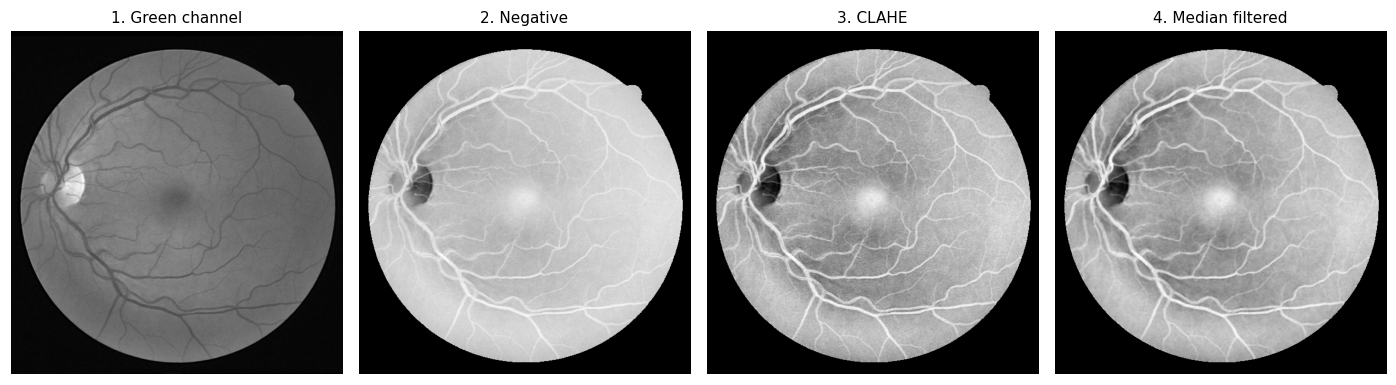

In [ ]:
def fill_outside_fov(img, fov):
    """Copy the nearest retina pixel into every pixel outside the FOV."""
    inner = ndi.binary_erosion(fov, iterations=3)   # skip the darkest rim pixels
    nearest = ndi.distance_transform_edt(~inner, return_indices=True)[1]
    return img[nearest[0], nearest[1]]


def equalize(img, fov, how):
    if how == "global":
        return exposure.equalize_hist(img, mask=fov)
    if how == "clahe":
        return exposure.equalize_adapthist(img, clip_limit=0.01)
    return img


def preprocess(rgb, fov):
    green = rgb[:, :, 1].astype(float) / 255.0                 # 1. green channel (0..1)
    negative = 1.0 - green                                      # 2. negative: s = (L-1) - r
    negative = fill_outside_fov(negative, fov)
    equalized = equalize(negative, fov, EQUALIZATION)           # 3. CLAHE (adaptive equalization)
    equalized = fill_outside_fov(equalized, fov)
    smoothed = ndi.median_filter(equalized, size=3)             # 4. 3x3 median filter
    return dict(green=green, negative=negative, equalized=equalized, smoothed=smoothed)


for d in data.values():
    d.update(preprocess(d["rgb"], d["fov"]))

show_row([ex["green"], ex["negative"] * ex["fov"], ex["equalized"] * ex["fov"], ex["smoothed"] * ex["fov"]],
         ["1. Green channel", "2. Negative", "3. CLAHE" if EQUALIZATION == "clahe" else "3. Histogram equalized", "4. Median filtered"],
         "fig2_preprocessing.png")

## 4. Vessel enhancement: Gaussian band-pass filter

1. Pad the image (reduces wrap-around artefacts at the borders)
2. **FFT** and **shift** so the zero frequency is in the centre
3. Build the filter **H(u,v)** and **multiply**: G(u,v) = H(u,v) · F(u,v)
4. **Shift back** and **inverse FFT**
5. Take the real part and remove the padding

A retina photo has three "layers" of frequencies:
- **very low**: uneven lighting (bright centre, dark edges) → remove
- **middle**: the vessels → keep
- **very high**: pixel noise → reduce

So we use a **band-pass** filter = Gaussian low-pass (cut-off `D_high`) multiplied by a
Gaussian high-pass (cut-off `D_low`):

H(u,v) = exp(-D²/2·D_high²) × (1 − exp(-D²/2·D_low²))

where D(u,v) is the distance from the centre of the spectrum.
Gaussian (smooth) filters are used instead of the "ideal" sharp-edged ones because sharp edges in H create ripple artefacts ("ringing") in the image.

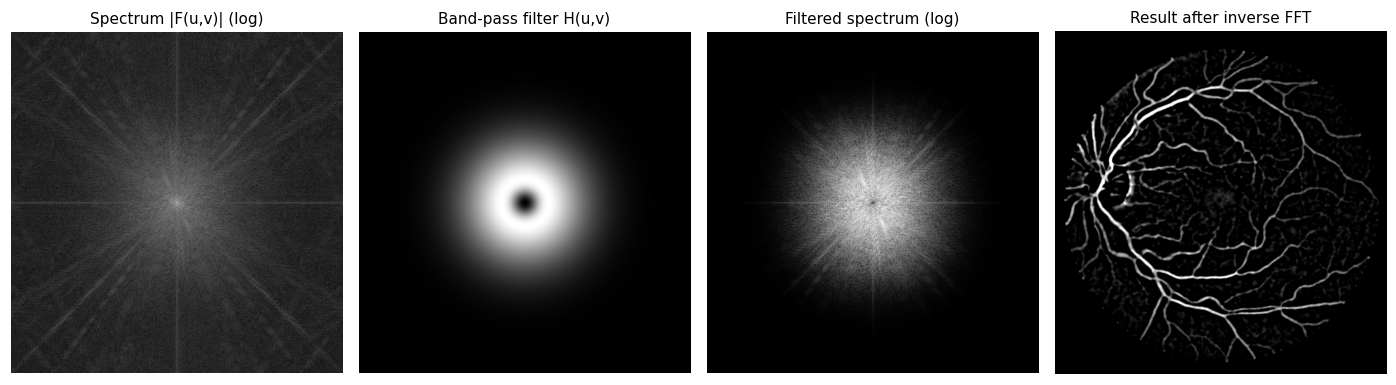

In [ ]:
PAD = 50


def to_frequency(img):
    """Pad the image, FFT it and shift it. Returns the spectrum and the (u, v) grid."""
    padded = np.pad(img, PAD, mode="reflect")
    F = np.fft.fftshift(np.fft.fft2(padded))
    M, N = padded.shape
    u = np.arange(M) - M // 2
    v = np.arange(N) - N // 2
    V, U = np.meshgrid(v, u)
    return F, U, V


def back_to_image(F, H):
    """Multiply by the filter H, shift back, inverse FFT and remove the padding."""
    G = H * F
    g = np.real(np.fft.ifft2(np.fft.ifftshift(G)))
    return g[PAD:-PAD, PAD:-PAD]


def bandpass_H(U, V, d_low, d_high):
    D2 = U ** 2 + V ** 2                            # squared distance from the centre, D(u,v)^2
    lowpass = np.exp(-D2 / (2 * d_high ** 2))       # keeps everything below d_high
    highpass = 1 - np.exp(-D2 / (2 * d_low ** 2))   # removes everything below d_low
    return lowpass * highpass


def enhance(img, d_low, d_high):
    F, U, V = to_frequency(img)
    H = bandpass_H(U, V, d_low, d_high)
    return np.maximum(back_to_image(F, H), 0)       # bright = vessel; negative values set to 0


F, U, V = to_frequency(ex["smoothed"])
H_demo = bandpass_H(U, V, 20, 80)
response_demo = enhance(ex["smoothed"], 20, 80)
show_row([np.log1p(np.abs(F)), H_demo, np.log1p(np.abs(H_demo * F)),
          np.clip(response_demo, 0, np.percentile(response_demo[ex["fov"]], 99.5)) * ex["fov"]],
         ["Spectrum |F(u,v)| (log)", "Band-pass filter H(u,v)", "Filtered spectrum (log)", "Result after inverse FFT"],
         "fig3_bandpass_steps.png")

### What the two settings do
- **D_low** is the size of the hole in the middle of the ring. Bigger = more of the
  uneven lighting is removed.
- **D_high** is the outer edge of the ring. Smaller = more noise removed, but thin
  vessels start to blur away.

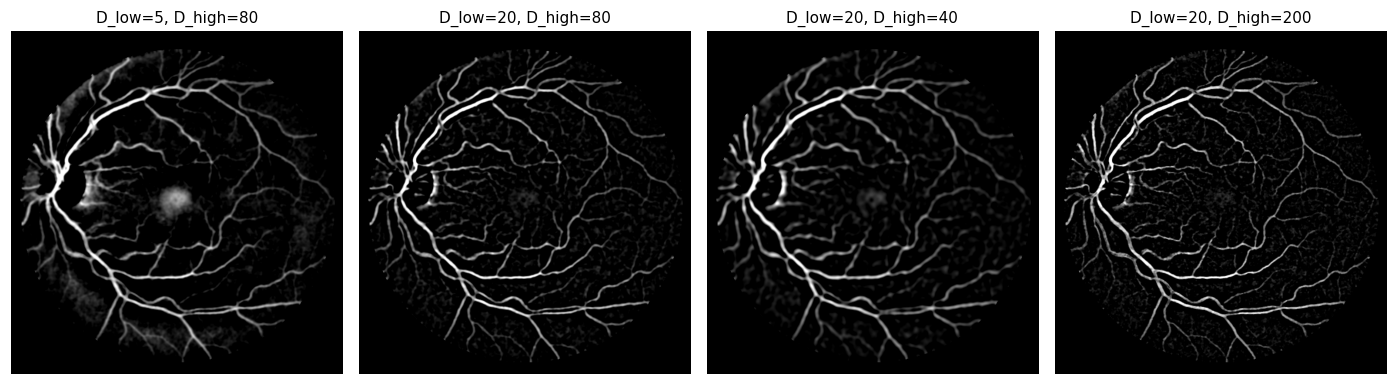

In [ ]:
examples = [(5, 80), (20, 80), (20, 40), (20, 200)]
show_row([np.clip(r, 0, np.percentile(r[ex["fov"]], 99.5)) * ex["fov"]
          for r in (enhance(ex["smoothed"], a, b) for a, b in examples)],
         [f"D_low={a}, D_high={b}" for a, b in examples],
         "fig4_bandpass_settings.png")

## 5. Thresholding and evaluation tools
- The filter output is scaled to 0–1 (inside the FOV) so one threshold works for all images.
- **Threshold** : pixel = vessel if response ≥ T.
- **Choosing T** on the tuning set, two possible rules (set `THRESHOLD_RULE`):
  - `"roc"`: the ROC point closest to the perfect corner (FPR = 0, TPR = 1), as Yue (2023)
    did. Because ~88% of pixels are background, this rule accepts many false vessels.
  - `"dice"` (default): the threshold that gives the best overlap (Dice) with the manual maps.
- **Removing specks:** after thresholding, isolated blobs smaller than `MIN_SPECK_SIZE`
  pixels are deleted, because real vessels are long connected structures. Each group of
  touching white pixels is labelled ("connected components"), counted, and removed if it
  is too small. Removing bigger blobs (e.g. under 100 pixels) was also tested, but it
  deleted real vessel pieces and lowered sensitivity, so 30 pixels is used.

**Metrics** (only pixels inside the FOV are counted):
- Sensitivity = TP / (TP + FN): share of real vessel pixels we found
- Specificity = TN / (TN + FP): share of background pixels correctly left as background
- Dice = 2TP / (2TP + FP + FN): overlap between our map and the manual map (1 = perfect)
- Accuracy = (TP + TN) / all. Misleading on its own, because ~88% of pixels are background
- AUC: area under the ROC curve, summarises all thresholds at once (1 = perfect, 0.5 = random)

In [ ]:
def normalise(resp, fov):
    lo, hi = np.percentile(resp[fov], [1, 99])
    return np.clip((resp - lo) / (hi - lo + 1e-12), 0, 1)


def remove_specks(binary, min_size):
    labels, n = ndi.label(binary, structure=np.ones((3, 3)))
    sizes = np.bincount(labels.ravel())
    keep = sizes >= min_size
    keep[0] = False
    return keep[labels]


def segment(resp, fov, T):
    seg = (resp >= T) & fov
    if REMOVE_SPECKS:
        seg = remove_specks(seg, MIN_SPECK_SIZE)
    return seg


def metrics(seg, truth, fov):
    s, t = seg[fov], truth[fov]
    tp = np.sum(s & t); tn = np.sum(~s & ~t)
    fp = np.sum(s & ~t); fn = np.sum(~s & t)
    return dict(Sensitivity=tp / (tp + fn), Specificity=tn / (tn + fp),
                Dice=2 * tp / (2 * tp + fp + fn), Accuracy=(tp + tn) / (tp + tn + fp + fn))


def pooled(ids, key):
    scores = np.concatenate([data[k][key][data[k]["fov"]] for k in ids])
    labels = np.concatenate([data[k]["truth"][data[k]["fov"]] for k in ids])
    return labels, scores


def best_roc_threshold(ids, key):
    labels, scores = pooled(ids, key)
    fpr, tpr, thr = roc_curve(labels, scores)
    i = np.argmin(np.sqrt(fpr ** 2 + (1 - tpr) ** 2))
    return float(thr[i]), roc_auc_score(labels, scores)


def best_dice_threshold(ids, key):
    labels, scores = pooled(ids, key)
    best_dice, best_T = 0, 0.5
    for T in np.arange(0.02, 0.9, 0.01):
        s = scores >= T
        tp = np.sum(s & labels); fp = np.sum(s & ~labels); fn = np.sum(~s & labels)
        dice = 2 * tp / (2 * tp + fp + fn)
        if dice > best_dice:
            best_dice, best_T = dice, float(T)
    return best_T

## 6. Choose the settings on the tuning set
We try 12 combinations of D_low and D_high and keep the one with the highest AUC on
the tuning set (images 21–40). Then we choose the threshold T, also on the tuning set.
The evaluation set is not touched here.

In [ ]:
print("AUC on the tuning set:")
results = {}
for d_low in (5, 10, 20):
    for d_high in (40, 80, 120, 200):
        labels, scores = [], []
        for k in tune_ids:
            d = data[k]
            r = normalise(enhance(d["smoothed"], d_low, d_high), d["fov"])
            labels.append(d["truth"][d["fov"]]); scores.append(r[d["fov"]])
        results[(d_low, d_high)] = roc_auc_score(np.concatenate(labels), np.concatenate(scores))
        print(f"  D_low = {d_low:3d}, D_high = {d_high:3d}: AUC = {results[(d_low, d_high)]:.4f}")
D_LOW, D_HIGH = max(results, key=results.get)
print(f"\nChosen filter: D_low = {D_LOW}, D_high = {D_HIGH}")

for d in data.values():
    d["response"] = normalise(enhance(d["smoothed"], D_LOW, D_HIGH), d["fov"])

T_roc, _ = best_roc_threshold(tune_ids, "response")
T = best_dice_threshold(tune_ids, "response") if THRESHOLD_RULE == "dice" else T_roc
print(f"Chosen threshold: T = {T:.2f} (rule: {THRESHOLD_RULE})")

AUC on the tuning set:
  D_low =   5, D_high =  40: AUC = 0.8153
  D_low =   5, D_high =  80: AUC = 0.8595
  D_low =   5, D_high = 120: AUC = 0.8679
  D_low =   5, D_high = 200: AUC = 0.8702
  D_low =  10, D_high =  40: AUC = 0.8621
  D_low =  10, D_high =  80: AUC = 0.8941
  D_low =  10, D_high = 120: AUC = 0.8976
  D_low =  10, D_high = 200: AUC = 0.8959
  D_low =  20, D_high =  40: AUC = 0.8873
  D_low =  20, D_high =  80: AUC = 0.9015
  D_low =  20, D_high = 120: AUC = 0.8984
  D_low =  20, D_high = 200: AUC = 0.8923

Chosen filter: D_low = 20, D_high = 80
Chosen threshold: T = 0.21 (rule: dice)


## 7. Results on the evaluation set
Mean ± standard deviation over the evaluation images. If your copy of DRIVE includes the
second expert's tracings (`2nd_manual`), a "Second human observer" row is added too:
that is the human-level target.

In [ ]:
rows = {"Band-pass filter (frequency domain)": []}
for k in test_ids:
    d = data[k]
    m = metrics(segment(d["response"], d["fov"], T), d["truth"], d["fov"])
    m["AUC"] = roc_auc_score(d["truth"][d["fov"]], d["response"][d["fov"]])
    rows["Band-pass filter (frequency domain)"].append(m)

obs2_ids = [k for k in test_ids if data[k]["obs2"] is not None]
if obs2_ids:
    rows["Second human observer"] = [metrics(data[k]["obs2"], data[k]["truth"], data[k]["fov"]) for k in obs2_ids]

cols = ["Dice", "Sensitivity", "Specificity", "Accuracy", "AUC"]
print(f"{'Method':38s}" + "".join(f"{c:>17s}" for c in cols))
csv_lines = ["Method," + ",".join(f"{c} mean,{c} SD" for c in cols)]
for name, per_image in rows.items():
    line, csv = f"{name:38s}", [name]
    for c in cols:
        vals = [m[c] for m in per_image if c in m]
        if vals:
            line += f"{np.mean(vals):>10.3f} ± {np.std(vals):.3f}"
            csv += [f"{np.mean(vals):.4f}", f"{np.std(vals):.4f}"]
        else:
            line += f"{'-':>17s}"; csv += ["", ""]
    print(line)
    csv_lines.append(",".join(csv))

with open(os.path.join(FIG_DIR, "results_table.csv"), "w") as f:
    f.write("\n".join(csv_lines))
print("\nFor comparison: Yue (2023) reported AUC = 0.75 on one DRIVE image; "
      "Staal et al. (2004) reported AUC = 0.952.")

Method                                             Dice      Sensitivity      Specificity         Accuracy              AUC
Band-pass filter (frequency domain)        0.711 ± 0.029     0.678 ± 0.051     0.968 ± 0.009     0.930 ± 0.007     0.908 ± 0.019

For comparison: Yue (2023) reported AUC = 0.75 on one DRIVE image; Staal et al. (2004) reported AUC = 0.952.


## 8. ROC curve on the evaluation set
The red dot marks the threshold that was chosen.

The straight line on the right part of the curve is expected: the filter's negative
values (clearly background) were all set to 0, so about a third of the pixels share the
same score. The curve can only jump across them in one straight step. Keeping the
negative values removes the straight line but gave a slightly lower Dice.

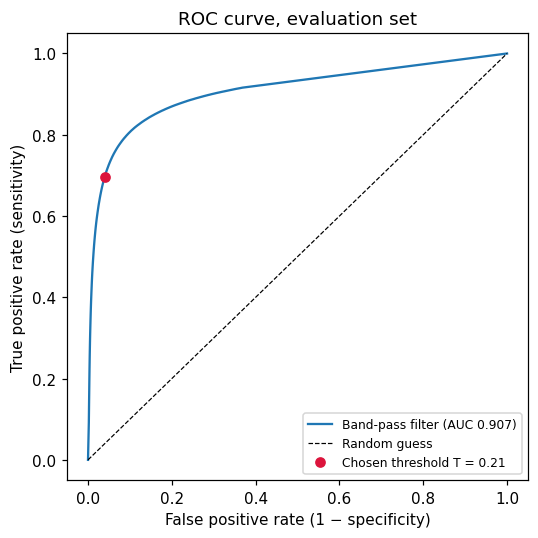

In [ ]:
labels, scores = pooled(test_ids, "response")
fpr, tpr, thr = roc_curve(labels, scores)
pred = scores >= T
dot_fpr = np.sum(pred & ~labels) / np.sum(~labels)
dot_tpr = np.sum(pred & labels) / np.sum(labels)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"Band-pass filter (AUC {roc_auc_score(labels, scores):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="Random guess")
plt.plot(dot_fpr, dot_tpr, "o", color="crimson", label=f"Chosen threshold T = {T:.2f}")
plt.xlabel("False positive rate (1 − specificity)")
plt.ylabel("True positive rate (sensitivity)")
plt.title("ROC curve, evaluation set")
plt.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig5_roc_curve.png"), dpi=200)
plt.show()

## 9. Visual results and error maps
Colours in the error maps:
**white** = vessel found correctly, **red** = false vessel (FP),
**blue** = missed vessel (FN), **black** = background correctly left out.

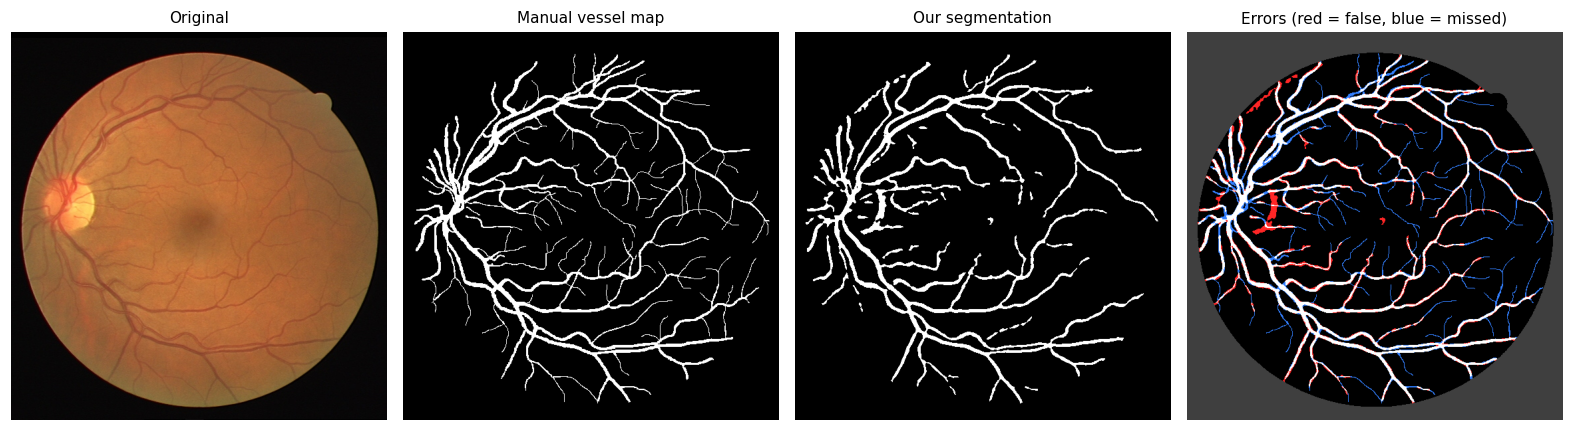

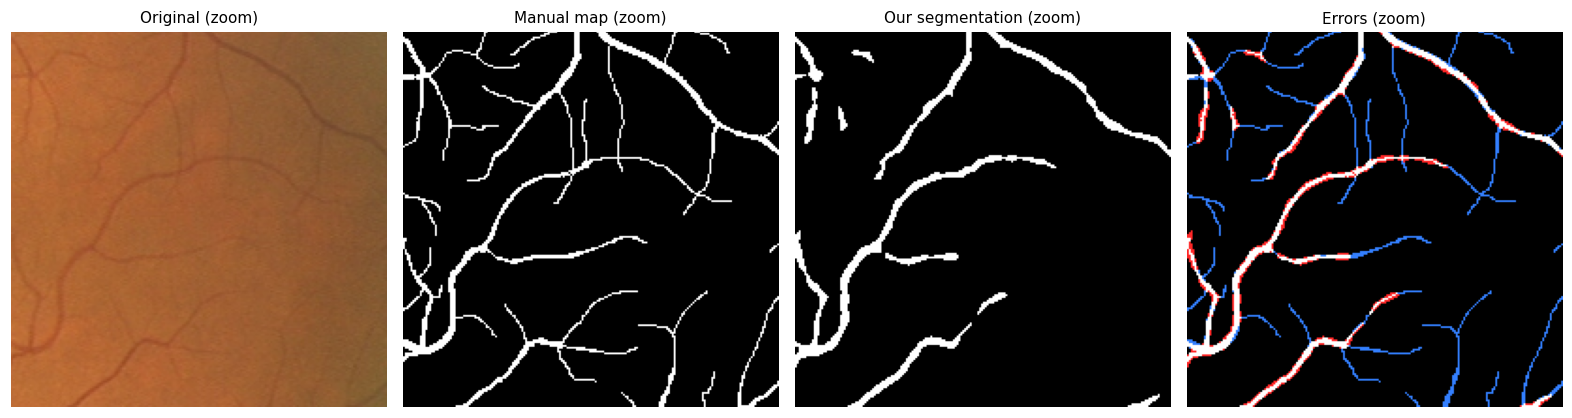

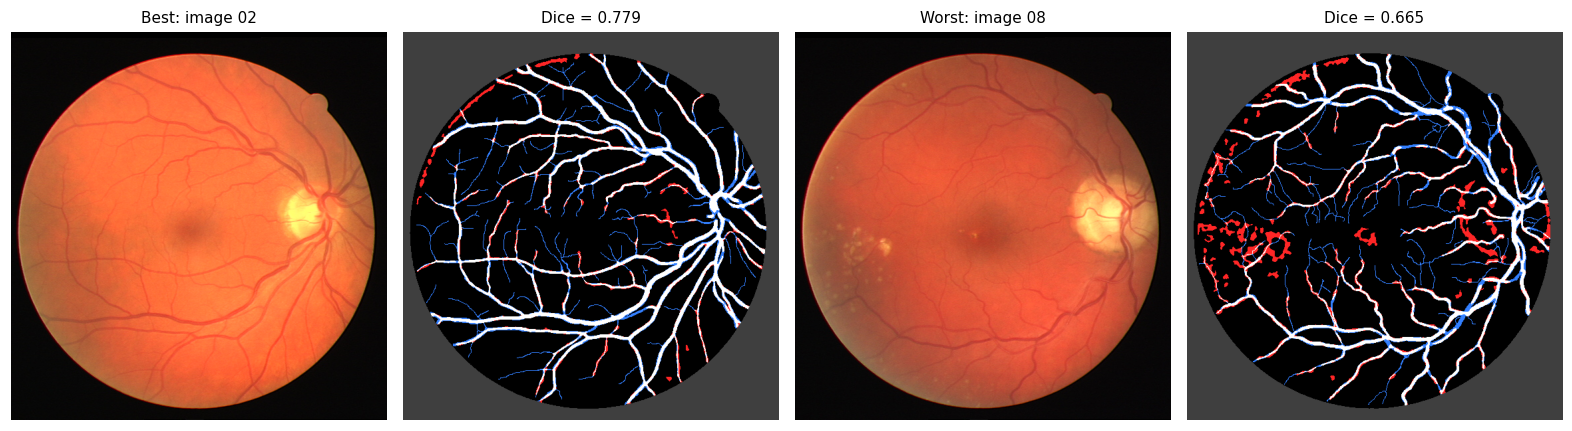

Figures and the results table were saved in the 'figures' folder.


In [ ]:
def error_map(seg, truth, fov):
    out = np.zeros(seg.shape + (3,))
    out[seg & truth] = (1, 1, 1)
    out[seg & ~truth] = (1, 0.15, 0.15)
    out[~seg & truth] = (0.2, 0.5, 1)
    out[~fov] = (0.25, 0.25, 0.25)
    return out


seg = segment(ex["response"], ex["fov"], T)
show_row([ex["rgb"], ex["truth"], seg, error_map(seg, ex["truth"], ex["fov"])],
         ["Original", "Manual vessel map", "Our segmentation", "Errors (red = false, blue = missed)"],
         "fig6_visual_results.png", size=3.6)

# Zoomed view of thin vessels (centre-right of the image)
zoom = (slice(200, 400), slice(330, 530))
show_row([ex["rgb"][zoom], ex["truth"][zoom], seg[zoom], error_map(seg, ex["truth"], ex["fov"])[zoom]],
         ["Original (zoom)", "Manual map (zoom)", "Our segmentation (zoom)", "Errors (zoom)"],
         "fig7_zoom_thin_vessels.png", size=3.6)

# Best and worst evaluation image by Dice
dice_per_image = {k: m["Dice"] for k, m in zip(test_ids, rows["Band-pass filter (frequency domain)"])}
best_id, worst_id = max(dice_per_image, key=dice_per_image.get), min(dice_per_image, key=dice_per_image.get)
imgs, titles = [], []
for k, label in ((best_id, "Best"), (worst_id, "Worst")):
    d = data[k]
    s = segment(d["response"], d["fov"], T)
    imgs += [d["rgb"], error_map(s, d["truth"], d["fov"])]
    titles += [f"{label}: image {k:02d}", f"Dice = {dice_per_image[k]:.3f}"]
show_row(imgs, titles, "fig8_best_and_worst.png", size=3.6)

print(f"Figures and the results table were saved in the '{FIG_DIR}' folder.")